In [1]:
# ============================================================
# CELL 1: Mount Google Drive & Install Dependencies
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

# Install all required packages
!pip install transformers datasets torch torchaudio scikit-learn \
             matplotlib seaborn umap-learn imbalanced-learn \
             pandas numpy nltk contractions emoji -q

print("✅ All packages installed!")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.7 MB/s eta 0:00:00
✅ All packages installed!


In [8]:
# ============================================================
# CELL 2: Imports & Configuration
# ============================================================
import os, re, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
warnings.filterwarnings('ignore')


import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

# Transformers
from transformers import AutoTokenizer, AutoModel
import torch

# Sklearn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
import umap

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')

# ─── CONFIG ───────────────────────────────────────────────

DRIVE_BASE = "/content/drive/MyDrive"

# Correct dataset path based on your folder
IEMOCAP_ROOT = f"{DRIVE_BASE}/IEMOCAP dataset/IEMOCAP_full_release_withoutVideos-001/IEMOCAP_full_release"

OUTPUT_DIR = f"{DRIVE_BASE}/emotion_project/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

EMOTIONS_KEEP = ['ang', 'hap', 'sad', 'neu', 'exc', 'fru']

EMOTION_MAP = {
    'ang': 'anger',
    'hap': 'happiness',
    'sad': 'sadness',
    'neu': 'neutral',
    'exc': 'excitement',
    'fru': 'frustration'
}

MAX_SEQ_LEN = 128
BERT_MODEL  = "bert-base-uncased"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dataset path:", IEMOCAP_ROOT)
print("Device:", device)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Dataset path: /content/drive/MyDrive/IEMOCAP dataset/IEMOCAP_full_release_withoutVideos-001/IEMOCAP_full_release
Device: cpu


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[n

In [9]:
# ============================================================
# CELL 3: IEMOCAP Parser — reads directly from Drive
# ============================================================
class IEMOCAPParser:
    """Parses IEMOCAP .txt transcription + emotion label files."""

    def __init__(self, root_path):
        self.root = root_path

    def parse_emotion_labels(self, label_file):
        emotions = {}
        with open(label_file, 'r') as f:
            for line in f:
                if line.startswith('['):
                    parts = line.strip().split('\t')
                    if len(parts) >= 4:
                        utt_id  = parts[1].strip()
                        emotion = parts[2].strip()
                        val_act_dom = parts[3].strip()
                        emotions[utt_id] = {
                            'emotion': emotion,
                            'val_act_dom': val_act_dom
                        }
        return emotions

    def parse_transcriptions(self, trans_file):
        transcriptions = {}
        with open(trans_file, 'r') as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith('#'):
                    continue
                parts = line.split(' ', 2)
                if len(parts) >= 3:
                    utt_id = parts[0]
                    text   = parts[2]
                    transcriptions[utt_id] = text
        return transcriptions

    def load_dataset(self):
        records = []
        sessions = [d for d in os.listdir(self.root)
                    if d.startswith('Session') and
                    os.path.isdir(os.path.join(self.root, d))]
        sessions.sort()
        print(f"Found sessions: {sessions}")

        for session in sessions:
            sess_path   = os.path.join(self.root, session)
            dialog_path = os.path.join(sess_path, 'dialog')
            emo_eval_path = os.path.join(dialog_path, 'EmoEvaluation')
            trans_path    = os.path.join(dialog_path, 'transcriptions')

            if not os.path.exists(emo_eval_path):
                print(f"  ⚠ Skipping {session} — no EmoEvaluation folder"); continue

            label_files = [f for f in os.listdir(emo_eval_path) if f.endswith('.txt')]
            for lf in label_files:
                dialog_id = lf.replace('.txt', '')
                lf_path   = os.path.join(emo_eval_path, lf)
                tf_path   = os.path.join(trans_path, dialog_id + '.txt')

                emotions = self.parse_emotion_labels(lf_path)
                transcriptions = self.parse_transcriptions(tf_path) if os.path.exists(tf_path) else {}

                for utt_id, emo_data in emotions.items():
                    emotion = emo_data['emotion']
                    if emotion not in EMOTIONS_KEEP:
                        continue
                    text = transcriptions.get(utt_id, '')
                    if not text:
                        continue
                    records.append({
                        'utterance_id': utt_id,
                        'session':      session,
                        'dialog_id':    dialog_id,
                        'text':         text,
                        'emotion':      emotion,
                        'emotion_label': EMOTION_MAP[emotion],
                        'val_act_dom':  emo_data['val_act_dom']
                    })

        df = pd.DataFrame(records)
        print(f"✅ Loaded {len(df)} utterances across {df['session'].nunique()} sessions")
        return df

parser = IEMOCAPParser(IEMOCAP_ROOT)
df_raw = parser.load_dataset()
df_raw.head()

Found sessions: ['Session1', 'Session2', 'Session3', 'Session4', 'Session5']
✅ Loaded 7380 utterances across 5 sessions


,utterance_id,session,dialog_id,text,emotion,emotion_label,val_act_dom
0,Ses01M_script01_2_F000,Session1,Ses01M_script01_2,Why did he invite her here?,ang,anger,"[2.5000, 2.5000, 3.0000]"
1,Ses01M_script01_2_F001,Session1,Ses01M_script01_2,It's been three and a half years. Why all of ...,ang,anger,"[2.5000, 2.0000, 3.0000]"
2,Ses01M_script01_2_F004,Session1,Ses01M_script01_2,"What is going on here, Joe?",ang,anger,"[1.5000, 4.0000, 4.0000]"
3,Ses01M_script01_2_F005,Session1,Ses01M_script01_2,The girl is not Larry's. If the girl is Larry...,ang,anger,"[1.5000, 4.5000, 5.0000]"
4,Ses01M_script01_2_F008,Session1,Ses01M_script01_2,Nobody in this house dares take away her faith...,fru,frustration,"[1.5000, 3.0000, 4.5000]"


In [11]:

# ============================================================
# CELL 4: Advanced Text Preprocessing Pipeline
# ============================================================

class AdvancedTextPreprocessor:
    def __init__(self):
        self.lemmatizer  = WordNetLemmatizer()
        self.stop_words  = set(stopwords.words('english')) - \
                           {'not','no','never','very','more','most','too'}

    def expand_contractions(self, text):
        return contractions.fix(text)

    def remove_noise(self, text):
        text = re.sub(r'\[.*?\]', ' ', text)
        text = re.sub(r'\(.*?\)', ' ', text)
        text = emoji.replace_emoji(text, replace=' ')
        text = re.sub(r'http\S+|www\S+', ' ', text)
        text = re.sub(r'[^a-zA-Z\s\'\-]', ' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        return text

    def normalize(self, text):
        text = text.lower()
        text = self.expand_contractions(text)
        return text

    def lemmatize_tokens(self, tokens):
        return [self.lemmatizer.lemmatize(t) for t in tokens
                if t not in self.stop_words and len(t) > 1]

    def preprocess(self, text):
        """Full pipeline → returns cleaned string."""
        try:
            text = self.remove_noise(text)
            text = self.normalize(text)
            try:
                tokens = word_tokenize(text)
            except Exception:
                tokens = text.split()
            tokens = self.lemmatize_tokens(tokens)
            return ' '.join(tokens)
        except Exception:
            return str(text).lower().strip()

    def preprocess_for_bert(self, text):
        """Lighter clean — preserve punctuation & case for BERT."""
        try:
            text = self.remove_noise(text)
            text = self.expand_contractions(text)
            text = re.sub(r'\s+', ' ', text).strip()
            return text
        except Exception:
            return str(text).strip()

    def extract_linguistic_features(self, text):
        try:
            try:
                tokens = word_tokenize(text.lower())
            except Exception:
                tokens = text.lower().split()
            try:
                pos_tags = nltk.pos_tag(tokens)
            except Exception:
                pos_tags = []
            return {
                'word_count':        len(tokens),
                'char_count':        len(text),
                'avg_word_len':      np.mean([len(t) for t in tokens]) if tokens else 0,
                'exclamation_count': text.count('!'),
                'question_count':    text.count('?'),
                'noun_ratio':        sum(1 for _,p in pos_tags if p.startswith('NN')) / max(len(tokens),1),
                'verb_ratio':        sum(1 for _,p in pos_tags if p.startswith('VB')) / max(len(tokens),1),
                'adj_ratio':         sum(1 for _,p in pos_tags if p.startswith('JJ')) / max(len(tokens),1),
                'unique_word_ratio': len(set(tokens)) / max(len(tokens),1),
            }
        except Exception:
            return {
                'word_count': 0, 'char_count': 0, 'avg_word_len': 0,
                'exclamation_count': 0, 'question_count': 0,
                'noun_ratio': 0, 'verb_ratio': 0, 'adj_ratio': 0,
                'unique_word_ratio': 0
            }

preprocessor = AdvancedTextPreprocessor()

# Apply both pipelines
print("Preprocessing text...")
df_raw['text_clean'] = df_raw['text'].apply(preprocessor.preprocess)
df_raw['text_bert']  = df_raw['text'].apply(preprocessor.preprocess_for_bert)

print("Extracting linguistic features...")
ling_features = df_raw['text'].apply(preprocessor.extract_linguistic_features)
ling_df       = pd.DataFrame(ling_features.tolist())
df_processed  = pd.concat([df_raw, ling_df], axis=1)

# Encode labels
le = LabelEncoder()
df_processed['label'] = le.fit_transform(df_processed['emotion'])
print(f"✅ Classes: {list(le.classes_)}")
print(df_processed[['text','text_clean','emotion','label']].head())

Preprocessing text...
Extracting linguistic features...
✅ Classes: ['ang', 'exc', 'fru', 'hap', 'neu', 'sad']
                                                text  \
0                        Why did he invite her here?   
1  It's been three and a half years.  Why all of ...   
2                        What is going on here, Joe?   
3  The girl is not Larry's.  If the girl is Larry...   
4  Nobody in this house dares take away her faith...   

                                          text_clean emotion  label  
0                                             invite     ang      0  
1                             three half year sudden     ang      0  
2                                          going joe     ang      0  
3  girl not larry 's girl larry 's girl not know not     ang      0  
4  nobody house dare take away faith joe her- str...     fru      2  


In [12]:
# ============================================================
# CELL 5: BERT Feature Extraction
# ============================================================
class BERTFeatureExtractor:
    def __init__(self, model_name=BERT_MODEL, batch_size=32):
        self.tokenizer  = AutoTokenizer.from_pretrained(model_name)
        self.model      = AutoModel.from_pretrained(model_name).to(device)
        self.model.eval()
        self.batch_size = batch_size

    @torch.no_grad()
    def extract(self, texts):
        all_cls, all_mean = [], []
        for i in range(0, len(texts), self.batch_size):
            batch = texts[i : i + self.batch_size]
            enc   = self.tokenizer(
                        batch, padding=True, truncation=True,
                        max_length=MAX_SEQ_LEN, return_tensors='pt'
                    ).to(device)
            out = self.model(**enc)
            cls_emb  = out.last_hidden_state[:, 0, :].cpu().numpy()
            mean_emb = out.last_hidden_state.mean(1).cpu().numpy()
            all_cls.append(cls_emb)
            all_mean.append(mean_emb)
            if (i // self.batch_size) % 5 == 0:
                print(f"  Processed {min(i+self.batch_size, len(texts))}/{len(texts)} utterances...")
        return np.vstack(all_cls), np.vstack(all_mean)

extractor = BERTFeatureExtractor()
print("Extracting BERT embeddings (5-10 mins on GPU, longer on CPU)...")
cls_embeddings, mean_embeddings = extractor.extract(df_processed['text_bert'].tolist())

# Combined feature matrix: CLS + mean pooling + linguistic
ling_array = df_processed[['word_count','char_count','avg_word_len',
                            'exclamation_count','question_count',
                            'noun_ratio','verb_ratio','adj_ratio',
                            'unique_word_ratio']].values
X_features = np.hstack([cls_embeddings, mean_embeddings, ling_array])
y_labels   = df_processed['label'].values

print(f"\n✅ CLS embeddings shape   : {cls_embeddings.shape}")
print(f"✅ Mean embeddings shape  : {mean_embeddings.shape}")
print(f"✅ Final feature matrix   : {X_features.shape}")
print(f"✅ Labels shape           : {y_labels.shape}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting BERT embeddings (5-10 mins on GPU, longer on CPU)...
  Processed 32/7380 utterances...
  Processed 192/7380 utterances...
  Processed 352/7380 utterances...
  Processed 512/7380 utterances...
  Processed 672/7380 utterances...
  Processed 832/7380 utterances...
  Processed 992/7380 utterances...
  Processed 1152/7380 utterances...
  Processed 1312/7380 utterances...
  Processed 1472/7380 utterances...
  Processed 1632/7380 utterances...
  Processed 1792/7380 utterances...
  Processed 1952/7380 utterances...
  Processed 2112/7380 utterances...
  Processed 2272/7380 utterances...
  Processed 2432/7380 utterances...
  Processed 2592/7380 utterances...
  Processed 2752/7380 utterances...
  Processed 2912/7380 utterances...
  Processed 3072/7380 utterances...
  Processed 3232/7380 utterances...
  Processed 3392/7380 utterances...
  Processed 3552/7380 utterances...
  Processed 3712/7380 utterances...
  Processed 3872/7380 utterances...
  Processed 4032/7380 utterances...
  Proces

✅ All files saved to Drive!


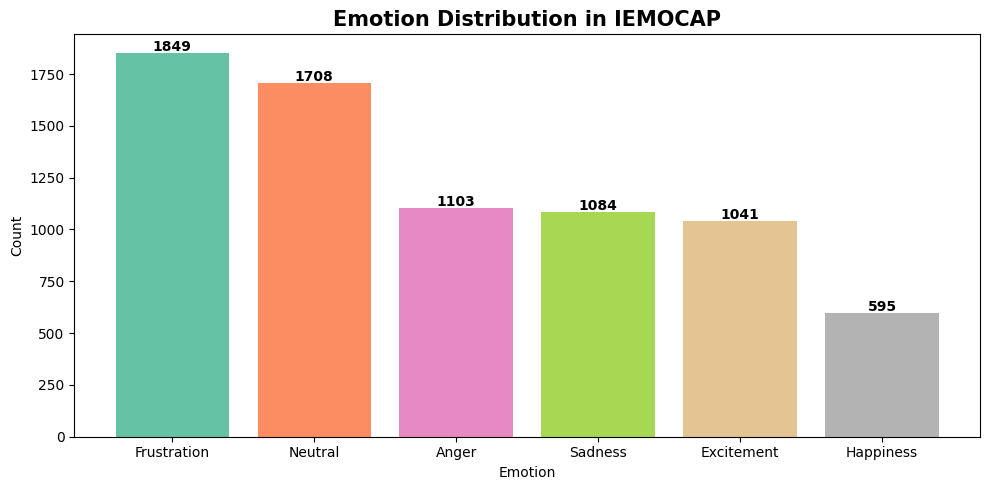

Computing t-SNE (2-3 mins)...


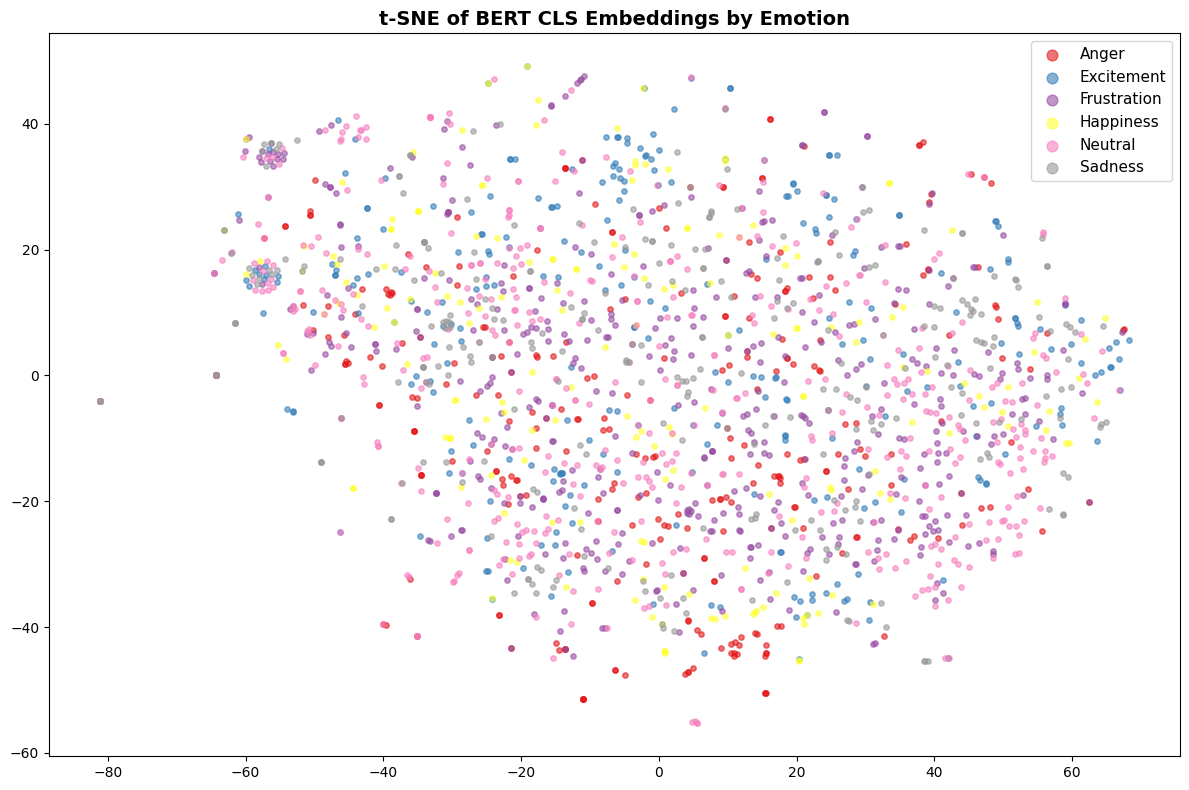

Computing UMAP...


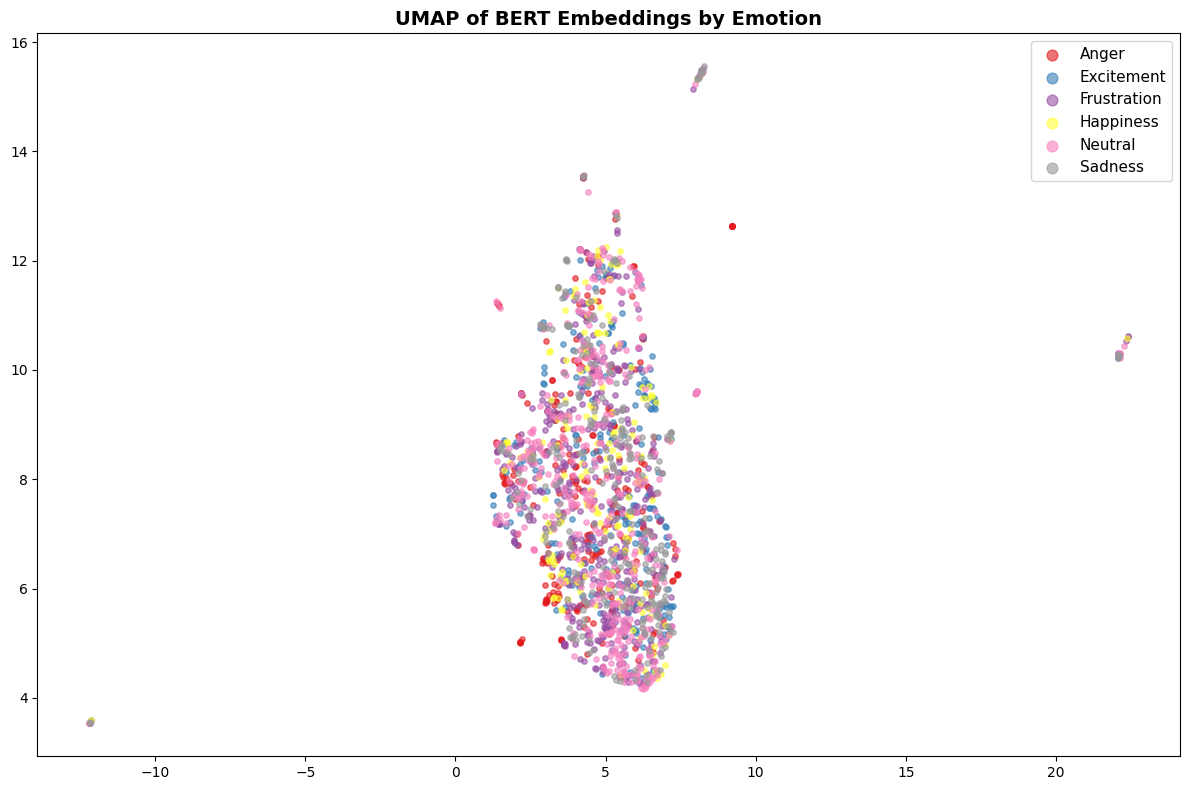

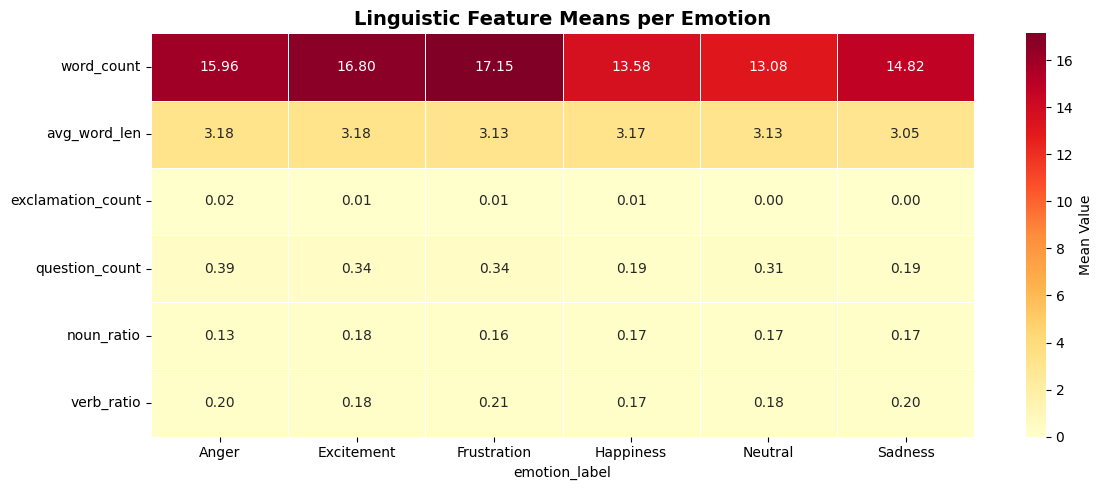


✅ Notebook 1 Complete!
   Saved to: /content/drive/MyDrive/emotion_project/outputs
   → Now open Notebook 2 for model training!


In [13]:
# ============================================================
# CELL 6: Save Clean Dataset + Visualisations
# ============================================================

# ── Save clean CSV & arrays
df_processed.to_csv(f'{OUTPUT_DIR}/iemocap_clean.csv', index=False)
np.save(f'{OUTPUT_DIR}/X_features.npy',    X_features)
np.save(f'{OUTPUT_DIR}/cls_embeddings.npy', cls_embeddings)
np.save(f'{OUTPUT_DIR}/y_labels.npy',       y_labels)
with open(f'{OUTPUT_DIR}/label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)
print("✅ All files saved to Drive!")

# ── Plot 1: Emotion Distribution
plt.figure(figsize=(10,5))
counts = df_processed['emotion'].value_counts()
emotion_full = {'ang':'Anger','exc':'Excitement','fru':'Frustration',
                'hap':'Happiness','neu':'Neutral','sad':'Sadness'}
labels_full  = [emotion_full.get(e, e) for e in counts.index]
bars = plt.bar(labels_full, counts.values,
               color=plt.cm.Set2(np.linspace(0,1,len(counts))))
plt.title('Emotion Distribution in IEMOCAP', fontsize=15, fontweight='bold')
plt.xlabel('Emotion'); plt.ylabel('Count')
for bar, v in zip(bars, counts.values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+10,
             str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/emotion_distribution.png', dpi=150)
plt.show()

# ── Plot 2: t-SNE of BERT embeddings
print("Computing t-SNE (2-3 mins)...")
sample_size = min(2000, len(cls_embeddings))
indices     = np.random.choice(len(cls_embeddings), sample_size, replace=False)
X_sample    = cls_embeddings[indices]
y_sample    = y_labels[indices]

tsne   = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_sample)

palette     = plt.cm.Set1(np.linspace(0, 1, len(le.classes_)))
label_names = le.inverse_transform(y_sample)

plt.figure(figsize=(12,8))
for i, emo in enumerate(le.classes_):
    mask = label_names == emo
    plt.scatter(X_tsne[mask,0], X_tsne[mask,1],
                c=[palette[i]], label=emotion_full.get(emo, emo),
                alpha=0.6, s=15)
plt.legend(markerscale=2, fontsize=11)
plt.title('t-SNE of BERT CLS Embeddings by Emotion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/tsne_bert.png', dpi=150)
plt.show()

# ── Plot 3: UMAP
print("Computing UMAP...")
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap  = reducer.fit_transform(X_sample)

plt.figure(figsize=(12,8))
for i, emo in enumerate(le.classes_):
    mask = label_names == emo
    plt.scatter(X_umap[mask,0], X_umap[mask,1],
                c=[palette[i]], label=emotion_full.get(emo, emo),
                alpha=0.6, s=15)
plt.legend(markerscale=2, fontsize=11)
plt.title('UMAP of BERT Embeddings by Emotion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/umap_bert.png', dpi=150)
plt.show()

# ── Plot 4: Linguistic features heatmap
plt.figure(figsize=(12,5))
df_processed['emotion_label'] = df_processed['emotion'].map(emotion_full)
ling_stats = df_processed.groupby('emotion_label')[
    ['word_count','avg_word_len','exclamation_count',
     'question_count','noun_ratio','verb_ratio']].mean()
sns.heatmap(ling_stats.T, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label':'Mean Value'})
plt.title('Linguistic Feature Means per Emotion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/linguistic_heatmap.png', dpi=150)
plt.show()

print("\n✅ Notebook 1 Complete!")
print(f"   Saved to: {OUTPUT_DIR}")
print("   → Now open Notebook 2 for model training!")

# RECOVERY CELL — run this instead of Cells 1-6 next time
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, pickle

OUTPUT_DIR = '/content/drive/MyDrive/emotion_project/outputs'

df_processed   = pd.read_csv(f'{OUTPUT_DIR}/iemocap_clean.csv')
X_features     = np.load(f'{OUTPUT_DIR}/X_features.npy')
cls_embeddings = np.load(f'{OUTPUT_DIR}/cls_embeddings.npy')
y_labels       = np.load(f'{OUTPUT_DIR}/y_labels.npy')

with open(f'{OUTPUT_DIR}/label_encoder.pkl', 'rb') as f:
    le = pickle.load(f)

print(f"✅ Loaded {len(df_processed)} utterances")
print(f"✅ Features: {X_features.shape}")
print(f"✅ Classes: {list(le.classes_)}")

In [16]:
import shutil, os
from google.colab import drive
drive.mount('/content/drive')

# ── Change this to your professor's shared folder path
# (Find it in drive.google.com → Shared with me → copy folder name exactly)
PROF_FOLDER = '/content/drive/MyDrive/Mini Project'

SOURCE = '/content/drive/MyDrive/emotion_project'

# Copy entire folder
dest = os.path.join(PROF_FOLDER, 'emotion_project')
shutil.copytree(SOURCE, dest, dirs_exist_ok=True)
print(f"✅ Copied to: {dest}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Copied to: /content/drive/MyDrive/Mini Project/emotion_project
